In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)

In [3]:
data = load_breast_cancer(as_frame=True)

df = data.frame

print("Размер датасета:", df.shape)
df.head()

Размер датасета: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
print("Количество объектов:", df.shape[0])
print("Количество признаков:", df.shape[1] - 1)

print("\nКлассы:")
print(df["target"].value_counts())

print("\nПропуски:")
print(df.isnull().sum().sum())

Количество объектов: 569
Количество признаков: 30

Классы:
target
1    357
0    212
Name: count, dtype: int64

Пропуски:
0


In [5]:
X = df.drop("target", axis=1)

y = 1 - df["target"]

print("Класс 1 = malignant")
print("Класс 0 = benign")

print("\nРаспределение классов:")
print(y.value_counts())

Класс 1 = malignant
Класс 0 = benign

Распределение классов:
target
0    357
1    212
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)
print("Размер y_train:", y_train.shape)
print("Размер y_test:", y_test.shape)

Размер X_train: (455, 30)
Размер X_test: (114, 30)
Размер y_train: (455,)
Размер y_test: (114,)


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Масштабирование выполнено.")

Масштабирование выполнено.


In [14]:
model = LogisticRegression(max_iter=5000)

model.fit(X_train_scaled, y_train)

print("Модель обучена.")

Модель обучена.


In [15]:
model = LogisticRegression(max_iter=5000)

model.fit(X_train_scaled, y_train)

print("Модель обучена.")

Модель обучена.


In [16]:
y_proba = model.predict_proba(X_test_scaled)[:, 1]

print(y_proba[:10])

[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [17]:
threshold_default = 0.5

y_pred_default = (y_proba >= threshold_default).astype(int)

print(y_pred_default[:20])

[0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]


In [18]:
print("Accuracy:", accuracy_score(y_test, y_pred_default))
print("Precision:", precision_score(y_test, y_pred_default))
print("Recall:", recall_score(y_test, y_pred_default))
print("F1-score:", f1_score(y_test, y_pred_default))


Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1-score: 0.9512195121951219


In [19]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)

roc_auc = roc_auc_score(y_test, y_proba)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.996031746031746


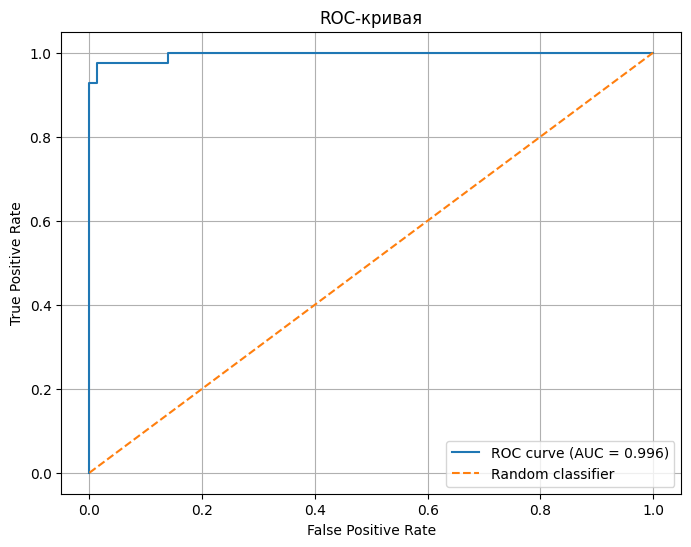

In [20]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC curve (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая")
plt.legend()
plt.grid()

plt.show()

In [21]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_proba
)

pr_auc = auc(recall, precision)

print("PR-AUC:", pr_auc)


PR-AUC: 0.994214569817921


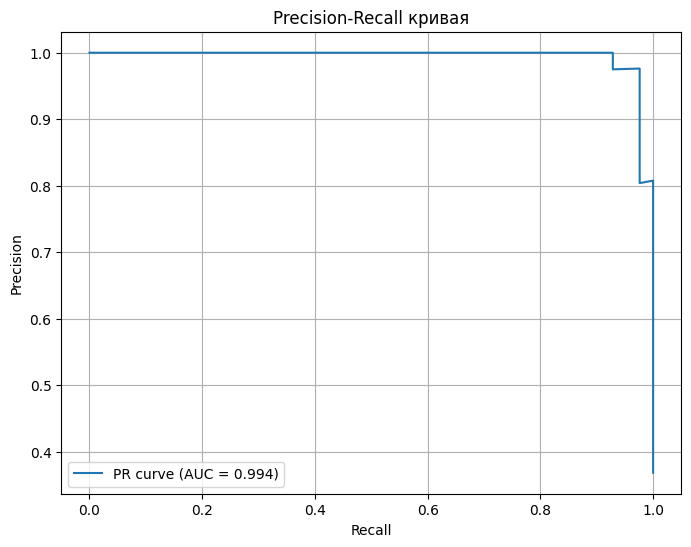

In [22]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"PR curve (AUC = {pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall кривая")
plt.legend()
plt.grid()

plt.show()

In [23]:
thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(results)

threshold_df.head(10)

,threshold,accuracy,precision,recall,f1,FP,FN
0,0.10,0.947368,0.891304,0.97619,0.931818,5,1
1,0.11,0.947368,0.891304,0.97619,0.931818,5,1
2,0.12,0.956140,0.911111,0.97619,0.942529,4,1
3,0.13,0.956140,0.911111,0.97619,0.942529,4,1
4,0.14,0.956140,0.911111,0.97619,0.942529,4,1
5,0.15,0.956140,0.911111,0.97619,0.942529,4,1
6,0.16,0.956140,0.911111,0.97619,0.942529,4,1
7,0.17,0.956140,0.911111,0.97619,0.942529,4,1
8,0.18,0.956140,0.911111,0.97619,0.942529,4,1
9,0.19,0.956140,0.911111,0.97619,0.942529,4,1


In [24]:
threshold_df[
    (threshold_df["threshold"] >= 0.20) &
    (threshold_df["threshold"] <= 0.50)
].round(3)

,threshold,accuracy,precision,recall,f1,FP,FN
11,0.21,0.965,0.932,0.976,0.953,3,1
12,0.22,0.965,0.932,0.976,0.953,3,1
13,0.23,0.974,0.953,0.976,0.965,2,1
14,0.24,0.982,0.976,0.976,0.976,1,1
15,0.25,0.982,0.976,0.976,0.976,1,1
16,0.26,0.982,0.976,0.976,0.976,1,1
17,0.27,0.982,0.976,0.976,0.976,1,1
18,0.28,0.982,0.976,0.976,0.976,1,1
19,0.29,0.982,0.976,0.976,0.976,1,1
20,0.30,0.982,0.976,0.976,0.976,1,1


In [25]:
threshold_df.sort_values(
    by=["FN", "FP"]
).head(10)

,threshold,accuracy,precision,recall,f1,FP,FN
14,0.24,0.982456,0.976190,0.97619,0.976190,1,1
15,0.25,0.982456,0.976190,0.97619,0.976190,1,1
16,0.26,0.982456,0.976190,0.97619,0.976190,1,1
17,0.27,0.982456,0.976190,0.97619,0.976190,1,1
18,0.28,0.982456,0.976190,0.97619,0.976190,1,1
19,0.29,0.982456,0.976190,0.97619,0.976190,1,1
20,0.30,0.982456,0.976190,0.97619,0.976190,1,1
21,0.31,0.982456,0.976190,0.97619,0.976190,1,1
13,0.23,0.973684,0.953488,0.97619,0.964706,2,1
11,0.21,0.964912,0.931818,0.97619,0.953488,3,1


In [26]:
COST_FP = 1
COST_FN = 5

threshold_df["cost"] = (
    threshold_df["FP"] * COST_FP +
    threshold_df["FN"] * COST_FN
)

threshold_df.sort_values("cost").head(10)

,threshold,accuracy,precision,recall,f1,FP,FN,cost
15,0.25,0.982456,0.976190,0.97619,0.976190,1,1,6
14,0.24,0.982456,0.976190,0.97619,0.976190,1,1,6
21,0.31,0.982456,0.976190,0.97619,0.976190,1,1,6
20,0.30,0.982456,0.976190,0.97619,0.976190,1,1,6
19,0.29,0.982456,0.976190,0.97619,0.976190,1,1,6
18,0.28,0.982456,0.976190,0.97619,0.976190,1,1,6
17,0.27,0.982456,0.976190,0.97619,0.976190,1,1,6
16,0.26,0.982456,0.976190,0.97619,0.976190,1,1,6
13,0.23,0.973684,0.953488,0.97619,0.964706,2,1,7
11,0.21,0.964912,0.931818,0.97619,0.953488,3,1,8


In [27]:
best_row = threshold_df.loc[
    threshold_df["cost"].idxmin()
]

best_threshold = best_row["threshold"]

print("Оптимальный порог:", best_threshold)
print("\nРезультаты:")
print(best_row)

Оптимальный порог: 0.23999999999999994

Результаты:
threshold    0.240000
accuracy     0.982456
precision    0.976190
recall       0.976190
f1           0.976190
FP           1.000000
FN           1.000000
cost         6.000000
Name: 14, dtype: float64


In [28]:
y_pred_optimal = (
    y_proba >= best_threshold
).astype(int)

In [29]:
comparison = pd.DataFrame({
    "Метрика": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "FP",
        "FN"
    ],

    "Порог 0.5": [
        accuracy_score(y_test, y_pred_default),
        precision_score(y_test, y_pred_default),
        recall_score(y_test, y_pred_default),
        f1_score(y_test, y_pred_default),
        confusion_matrix(y_test, y_pred_default).ravel()[1],
        confusion_matrix(y_test, y_pred_default).ravel()[2]
    ],

    "Оптимальный порог": [
        accuracy_score(y_test, y_pred_optimal),
        precision_score(y_test, y_pred_optimal),
        recall_score(y_test, y_pred_optimal),
        f1_score(y_test, y_pred_optimal),
        confusion_matrix(y_test, y_pred_optimal).ravel()[1],
        confusion_matrix(y_test, y_pred_optimal).ravel()[2]
    ]
})

comparison.round(3)

,Метрика,Порог 0.5,Оптимальный порог
0,Accuracy,0.965,0.982
1,Precision,0.975,0.976
2,Recall,0.929,0.976
3,F1-score,0.951,0.976
4,FP,1.000,1.000
5,FN,3.000,1.000


In [30]:
cm_optimal = confusion_matrix(
    y_test,
    y_pred_optimal
)

cm_optimal_df = pd.DataFrame(
    cm_optimal,
    index=[
        "Фактически benign",
        "Фактически malignant"
    ],
    columns=[
        "Предсказано benign",
        "Предсказано malignant"
    ]
)

cm_optimal_df

,Предсказано benign,Предсказано malignant
Фактически benign,71,1
Фактически malignant,1,41


In [31]:
cm_optimal = confusion_matrix(
    y_test,
    y_pred_optimal
)

cm_optimal_df = pd.DataFrame(
    cm_optimal,
    index=[
        "Фактически benign",
        "Фактически malignant"
    ],
    columns=[
        "Предсказано benign",
        "Предсказано malignant"
    ]
)

cm_optimal_df

,Предсказано benign,Предсказано malignant
Фактически benign,71,1
Фактически malignant,1,41


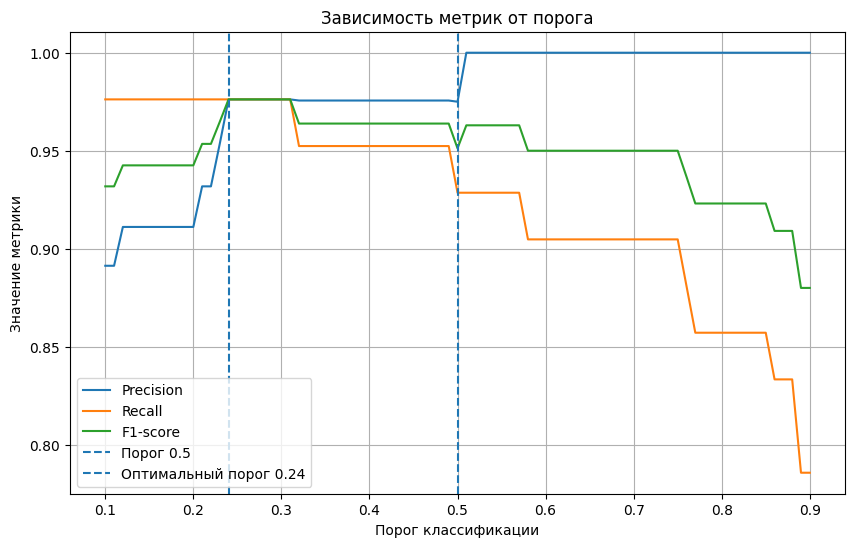

In [32]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1-score"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Порог 0.5"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Оптимальный порог {best_threshold:.2f}"
)

plt.xlabel("Порог классификации")
plt.ylabel("Значение метрики")
plt.title("Зависимость метрик от порога")
plt.legend()
plt.grid()

plt.show()

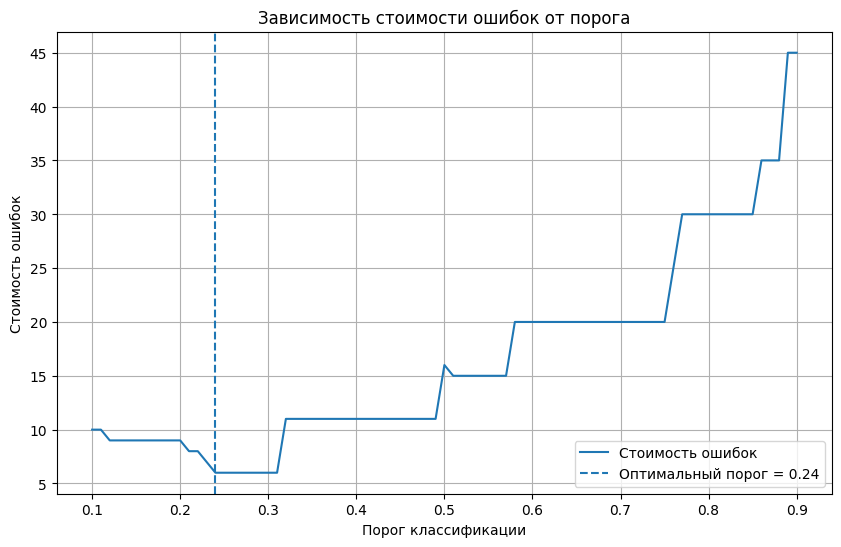

In [33]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["cost"],
    label="Стоимость ошибок"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Оптимальный порог = {best_threshold:.2f}"
)

plt.xlabel("Порог классификации")
plt.ylabel("Стоимость ошибок")
plt.title("Зависимость стоимости ошибок от порога")
plt.legend()
plt.grid()

plt.show()

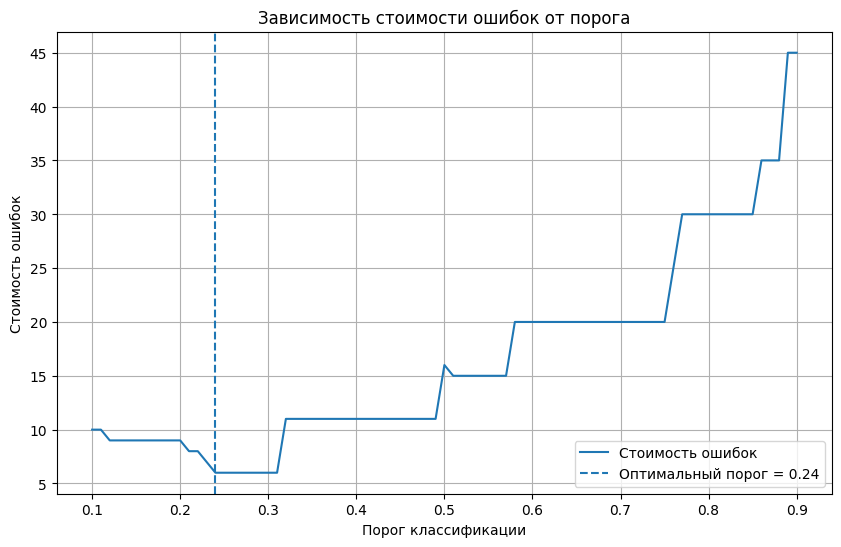

In [34]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["cost"],
    label="Стоимость ошибок"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Оптимальный порог = {best_threshold:.2f}"
)

plt.xlabel("Порог классификации")
plt.ylabel("Стоимость ошибок")
plt.title("Зависимость стоимости ошибок от порога")
plt.legend()
plt.grid()

plt.show()

В работе была построена модель бинарной классификации на основе логистической регрессии. В отличие от обычного бинарного предсказания, с помощью метода predict_proba() были получены вероятности принадлежности объектов к положительному классу.

Для оценки качества модели были построены ROC- и Precision-Recall кривые, а также рассчитаны ROC-AUC и PR-AUC.

Стандартный порог классификации 0,5 был изменён, поскольку в рассматриваемой задаче ложноотрицательная ошибка является более критичной, чем ложноположительная. Ложноотрицательная ошибка означает, что злокачественная опухоль была классифицирована как доброкачественная.

Для учёта цены ошибок была задана стоимость FP = 1 и FN = 5. Для различных значений порога была рассчитана суммарная стоимость ошибок:

Cost = FP × 1 + FN × 5

Оптимальным был выбран порог, при котором данная стоимость минимальна.

В результате изменение порога позволило уменьшить влияние наиболее дорогой ошибки FN, допустив при этом некоторое увеличение количества FP. Поэтому в данной задаче использование подобранного порога является более обоснованным, чем автоматическое использование стандартного значения 0,5.